# Parameter identification with data fitting
**Robotics · Week 5 · Assignment 1**  
**Sanjar · Student ID 240048**

I analysed the encoder recordings to see how motors M4 and M3 respond to different PWM commands. I started with the low-power steps, then used the square wave and chirp to check how well a simple motor model follows changing inputs.

| Column | Meaning | Unit |
|---|---|---|
| 0 | Encoder angle | degrees |
| 1 | Recorded time | milliseconds |
| 2 | Commanded motor power | % PWM |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, least_squares
from IPython.display import display, Markdown, HTML

FILES = {
    'M4 steps': 'js111_steps_M4.txt',
    'M4 repeat': 'js222_steps_M4_repeat.txt',
    'M3 steps': 'js333_steps_M3.txt',
    'M4 square': 'js444_square_M4.txt',
    'M3 square': 'js555_square_M3.txt',
    'M4 chirp': 'js666_chirp_M4.txt',
    'M3 chirp': 'js777_chirp_M3.txt',
    'M4 low PWM': 'js888_deadzone_M4.txt',
    'M3 low PWM': 'js999_deadzone_M3.txt',
}
data_dir = next((p for p in [Path('motor_data'), Path('.')]
                 if all((p / name).exists() for name in FILES.values())), None)
if data_dir is None:
    try:
        from google.colab import files
        files.upload()
        data_dir = Path('.')
    except ImportError:
        raise FileNotFoundError('Put the nine recordings in motor_data beside this notebook.')

plt.rcParams.update({'figure.dpi': 115, 'font.size': 10, 'axes.grid': True,
                     'grid.alpha': 0.22, 'axes.spines.top': False})
motor_colors = {'M4': '#2672b8', 'M3': '#d15a37'}
direction_colors = {'Forward': '#2672b8', 'Backward': '#d15a37'}

def show_table(frame, digits=3):
    display(HTML(frame.to_html(index=False, na_rep='—', border=0,
                              float_format=lambda value: f'{value:.{digits}f}')))

data = {}
overview = []
for label, name in FILES.items():
    a = np.loadtxt(data_dir / name, delimiter=',')
    assert a.ndim == 2 and a.shape[1] == 3
    assert np.isfinite(a).all() and np.all(np.diff(a[:, 1]) > 0)
    data[label] = a
    overview.append([label, len(a), (a[-1, 1] - a[0, 1]) / 1000,
                     a[:, 2].min(), a[:, 2].max()])
show_table(pd.DataFrame(overview, columns=['Recording', 'Samples', 'Duration (s)',
                                          'Minimum PWM (%)', 'Maximum PWM (%)']))


Recording,Samples,Duration (s),Minimum PWM (%),Maximum PWM (%)
M4 steps,101,2.976,0.000,0.000
M4 repeat,93,2.975,0.000,0.000
M3 steps,97,2.994,0.000,0.000
M4 square,199,8.965,-60.000,60.000
M3 square,201,9.011,-60.000,60.000
M4 chirp,182,9.028,-60.000,60.000
M3 chirp,199,8.996,-60.000,60.000
M4 low PWM,1907,57.194,-9.000,9.000
M3 low PWM,1835,57.227,-9.000,9.000


## Motor model

I used a first-order model, where the motor gradually approaches a steady speed:

$$T_m\frac{d\omega}{dt}+\omega=\frac{U}{k_e}, \qquad \frac{d\theta}{dt}=\omega.$$

| Symbol | Meaning | Unit |
|---|---|---|
| $\theta$ | How far the shaft has turned | rad |
| $\omega$ | Shaft angular speed | rad/s |
| $\omega_{ss}$ | Speed after the initial acceleration | rad/s |
| $T_m$ | Time to reach about 63% of the final speed from rest | s |
| $U$ | Applied motor voltage | V |
| $k_e$ | Voltage-to-speed constant in this model | V·s/rad |

For a constant input, $\omega_{ss}=U/k_e$. Multiplying the speed equation by $e^{t/T_m}$ gives

$$\frac{d}{dt}\left(\omega e^{t/T_m}\right)=\frac{\omega_{ss}}{T_m}e^{t/T_m}.$$

After integration, using $\omega(0)=0$,

$$\omega(t)=\omega_{ss}\left(1-e^{-t/T_m}\right).$$

Integrating speed from 0 to $t$, with $\theta(0)=0$, gives the angle equation:

$$\theta(t)=\omega_{ss}\left(t-T_m+T_m e^{-t/T_m}\right).$$

This model neglects armature inductance and assumes a constant load, constant voltage within a step and approximately linear friction. It is a simple approximation, so I check its predictions against the measured curves.


## Step responses

Each low-power recording contains 18 powered steps, from −9% to +9% PWM, excluding zero. The motor runs for about two seconds at each level, followed by about one second at zero PWM. I split the recording whenever the command changes and fit each powered step separately.

I subtract the first time and angle in each segment before fitting. Since that first reading comes slightly after the command, the fitted time constant has some timing uncertainty. The tables show the fitted values and their standard errors; these errors describe the curve fit, not every possible measurement error.


In [2]:
def split_by_pwm(a):
    return np.split(a, np.flatnonzero(np.diff(a[:, 2])) + 1)

def step_model(t, speed, T_m):
    return speed * (t - T_m + T_m * np.exp(-t / T_m))

step_rows, step_segments = [], {}
for motor in ['M4', 'M3']:
    for segment in split_by_pwm(data[f'{motor} low PWM']):
        pwm = int(segment[0, 2])
        if pwm == 0:
            continue
        t = (segment[:, 1] - segment[0, 1]) / 1000
        angle = np.deg2rad(segment[:, 0] - segment[0, 0])
        tail = t >= t[-1] - 0.5
        tail_speed = np.polyfit(t[tail], angle[tail], 1)[0]
        moved = np.ptp(segment[:, 0]) >= 2  # Count movement once the encoder changes by at least two degrees.
        speed = T_m = speed_se = T_se = rmse = np.nan
        status = 'No movement'
        if moved:
            fitted, covariance = curve_fit(
                step_model, t, angle, p0=[angle[-1] / t[-1], 0.3],
                bounds=([-100, 0.001], [100, 3]), maxfev=20000)
            speed, T_m = fitted
            speed_se, T_se = np.sqrt(np.diag(covariance))
            rmse = np.sqrt(np.mean((angle - step_model(t, *fitted)) ** 2))
            status = 'Poor fit / unresolved T' if T_m < 2 * np.median(np.diff(t)) else 'Fitted'
        step_segments[motor, pwm] = (t, angle)
        step_rows.append([motor, pwm, speed, speed_se, T_m, T_se,
                          tail_speed, rmse, np.ptp(segment[:, 0]), status])

steps = pd.DataFrame(step_rows, columns=['Motor', 'PWM (%)', 'Speed (rad/s)',
    'Speed SE', 'T (s)', 'T SE', 'Tail speed (rad/s)', 'Angle RMSE (rad)',
    'Angle range (deg)', 'Status'])
for motor in ['M4', 'M3']:
    display(Markdown(f'### {motor} step estimates'))
    show_table(steps.loc[steps['Motor'] == motor,
        ['PWM (%)', 'Speed (rad/s)', 'Speed SE', 'T (s)', 'T SE', 'Angle RMSE (rad)', 'Status']])


### M4 step estimates

PWM (%),Speed (rad/s),Speed SE,T (s),T SE,Angle RMSE (rad),Status
-9,-3.329,0.004,0.309,0.001,0.009,Fitted
-8,-3.346,0.004,0.284,0.001,0.008,Fitted
-7,-3.399,0.005,0.281,0.002,0.011,Fitted
-6,-3.417,0.005,0.338,0.002,0.009,Fitted
-5,-2.520,0.016,0.509,0.008,0.020,Fitted
-4,-2.310,0.007,0.492,0.004,0.009,Fitted
-3,-2.278,0.005,0.362,0.003,0.008,Fitted
-2,-2.305,0.006,0.309,0.003,0.012,Fitted
-1,—,—,—,—,—,No movement
1,2.569,0.103,0.001,0.046,0.472,Poor fit / unresolved T


### M3 step estimates

PWM (%),Speed (rad/s),Speed SE,T (s),T SE,Angle RMSE (rad),Status
-9,-4.009,0.006,0.483,0.002,0.008,Fitted
-8,-3.952,0.014,0.482,0.005,0.018,Fitted
-7,-3.769,0.007,0.306,0.002,0.015,Fitted
-6,-4.126,0.013,0.509,0.004,0.015,Fitted
-5,-2.827,0.014,0.618,0.007,0.013,Fitted
-4,-2.985,0.010,0.685,0.005,0.008,Fitted
-3,-2.738,0.009,0.606,0.004,0.008,Fitted
-2,-2.511,0.006,0.310,0.003,0.012,Fitted
-1,-1.385,0.022,0.794,0.023,0.013,Fitted
1,0.992,0.006,0.442,0.008,0.009,Fitted


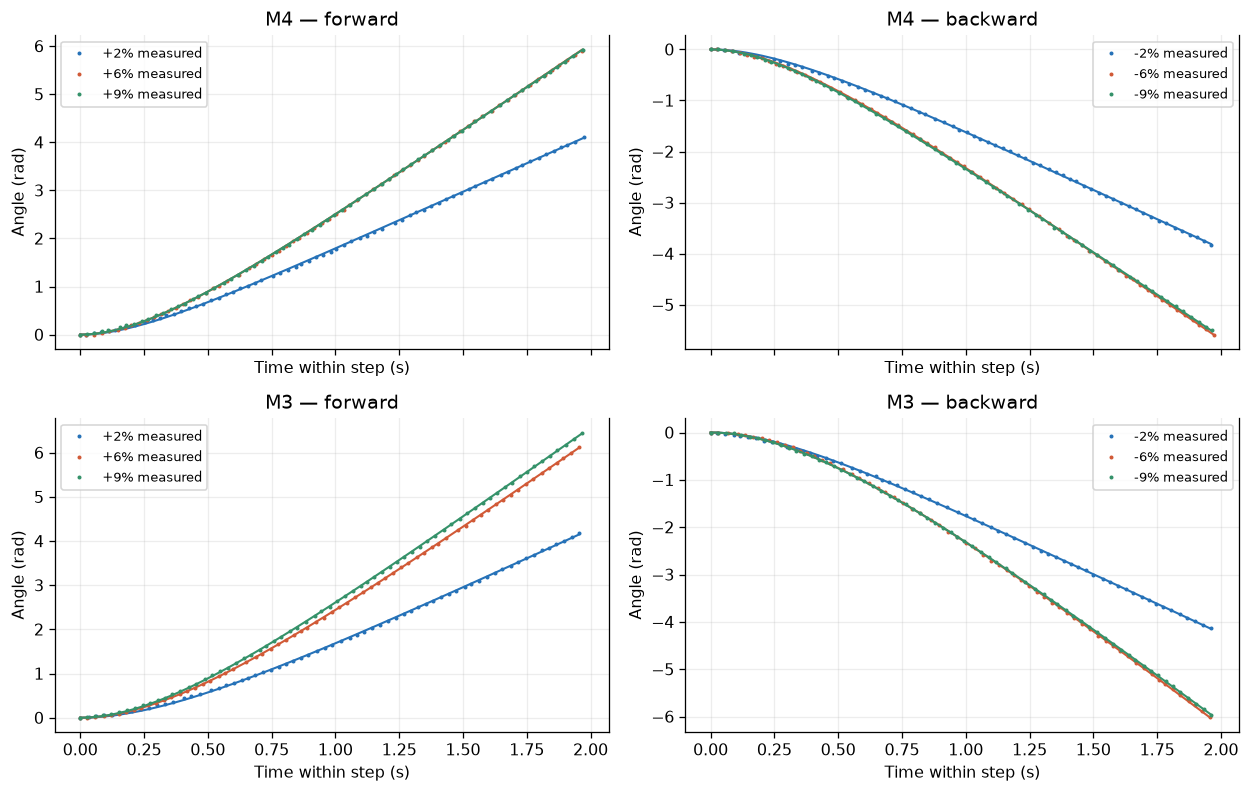

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for row, motor in enumerate(['M4', 'M3']):
    for col, sign in enumerate([1, -1]):
        ax = axes[row, col]
        for level, color in zip([2, 6, 9], ['#2672b8', '#d15a37', '#35926a']):
            pwm = sign * level
            t, angle = step_segments[motor, pwm]
            result = steps[(steps['Motor'] == motor) & (steps['PWM (%)'] == pwm)].iloc[0]
            ax.plot(t, angle, '.', color=color, ms=3, label=f'{pwm:+d}% measured')
            ax.plot(t, step_model(t, result['Speed (rad/s)'], result['T (s)']),
                    '-', color=color, lw=1.3)
        ax.set(title=f'{motor} — {"forward" if sign > 0 else "backward"}',
               xlabel='Time within step (s)', ylabel='Angle (rad)')
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


*The dots show the measured angles and the lines show the fitted curves. Most of these steps follow the model closely, although the fitted parameters change with PWM.*

## Speed and time constant against PWM

These plots cover the measured range of −9% to +9%. I fit a straight line over 2–9% in each direction, leaving out the three poorly resolved fits. The speeds form plateaus, so I would not extend these lines to much higher PWM values. The $R^2$ values show how well each line describes the points used in its fit.

To estimate the dead zone, I compare the last command with no movement and the first command that moves the motor. M4 stays still at −1% but moves at −2%. The other directions already move at the smallest nonzero command tested. Since PWM changes in steps of 1%, I report a range for each threshold.


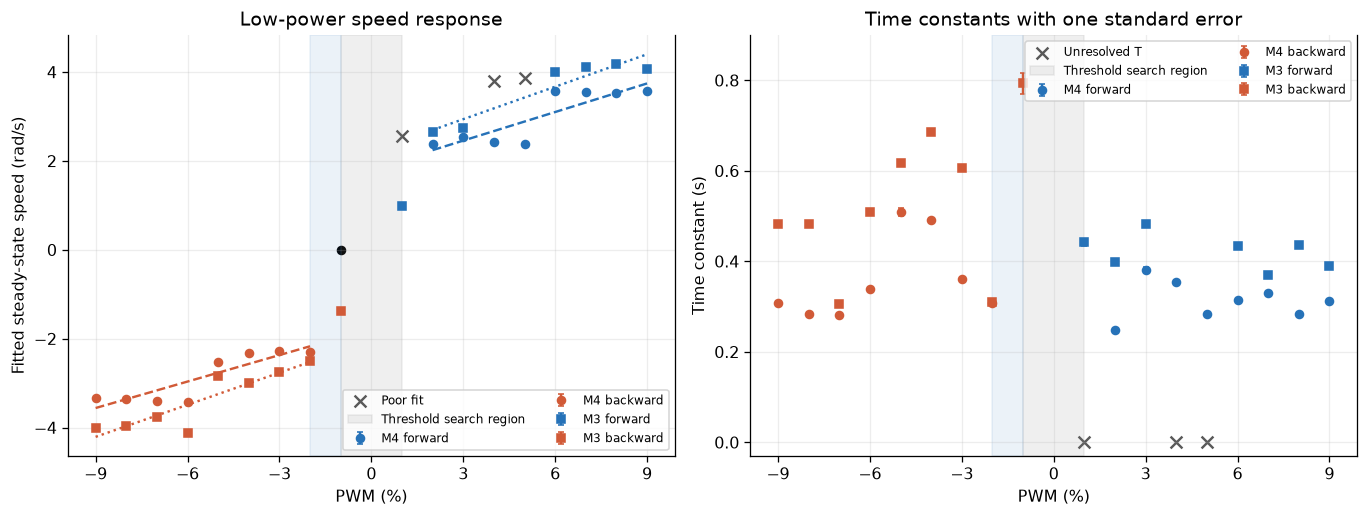

### M4 parameter summary

Direction,Threshold (% PWM),Low-range slope (rad/s per %),Line R²,Mean T (s)
Forward,"(0, 1]",0.214,0.745,0.314
Backward,"(1, 2]",0.198,0.780,0.361


### M3 parameter summary

Direction,Threshold (% PWM),Low-range slope (rad/s per %),Line R²,Mean T (s)
Forward,"(0, 1]",0.243,0.883,0.422
Backward,"(0, 1]",0.241,0.795,0.532


In [4]:
# Use the last still command and the first moving command to bracket each threshold.
deadzone = {('M4', 'Forward'): (0, 1), ('M4', 'Backward'): (1, 2),
            ('M3', 'Forward'): (0, 1), ('M3', 'Backward'): (0, 1)}
linear_params = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for motor, marker in [('M4', 'o'), ('M3', 's')]:
    for direction, sign in [('Forward', 1), ('Backward', -1)]:
        color = direction_colors[direction]
        rows = steps[(steps['Motor'] == motor) & (steps['PWM (%)'] * sign > 0)]
        good = rows[rows['Status'] == 'Fitted']
        linear = good[good['PWM (%)'].abs() >= 2]
        slope, intercept = np.polyfit(linear['PWM (%)'], linear['Speed (rad/s)'], 1)
        residual = linear['Speed (rad/s)'] - (slope * linear['PWM (%)'] + intercept)
        r2 = 1 - np.sum(residual**2) / np.sum((linear['Speed (rad/s)'] - linear['Speed (rad/s)'].mean())**2)
        linear_params[motor, direction] = dict(slope=slope, intercept=intercept, r2=r2,
                                               T=good['T (s)'].mean(), T_std=good['T (s)'].std())
        label = f'{motor} {direction.lower()}'
        axes[0].errorbar(good['PWM (%)'], good['Speed (rad/s)'], yerr=good['Speed SE'],
                         fmt=marker, color=color, capsize=2, ms=5, label=label)
        xx = np.array([linear['PWM (%)'].min(), linear['PWM (%)'].max()])
        axes[0].plot(xx, slope * xx + intercept, '--' if motor == 'M4' else ':', color=color)
        axes[1].errorbar(good['PWM (%)'], good['T (s)'], yerr=good['T SE'],
                         fmt=marker, color=color, capsize=2, ms=5, label=label)
bad = steps[steps['Status'] == 'Poor fit / unresolved T']
axes[0].scatter(bad['PWM (%)'], bad['Speed (rad/s)'], marker='x', s=55, color='0.35', label='Poor fit')
axes[1].scatter(bad['PWM (%)'], bad['T (s)'], marker='x', s=55, color='0.35', label='Unresolved T')
axes[0].scatter([-1], [0], color='black', marker='o', s=25)
for ax in axes:
    ax.axvspan(-1, 1, color='grey', alpha=0.12, label='Threshold search region')
    ax.axvspan(-2, -1, color='#2672b8', alpha=0.09)
    ax.set(xlabel='PWM (%)', xticks=np.arange(-9, 10, 3))
axes[0].set(ylabel='Fitted steady-state speed (rad/s)', title='Low-power speed response')
axes[1].set(ylabel='Time constant (s)', title='Time constants with one standard error', ylim=(-0.03, 0.9))
axes[0].legend(fontsize=7.5, ncol=2)
axes[1].legend(fontsize=7.5, ncol=2)
fig.tight_layout()
plt.show()

for motor in ['M4', 'M3']:
    rows = []
    for direction in ['Forward', 'Backward']:
        p = linear_params[motor, direction]
        lo, hi = deadzone[motor, direction]
        rows.append([direction, f'({lo}, {hi}]', p['slope'], p['r2'], p['T']])
    display(Markdown(f'### {motor} parameter summary'))
    show_table(pd.DataFrame(rows, columns=['Direction', 'Threshold (% PWM)',
        'Low-range slope (rad/s per %)', 'Line R²', 'Mean T (s)']))


*Colours show the direction and marker shapes show the motor. The shaded area marks the threshold ranges. Gray crosses show the poor fits, which are left out of the fitted lines and mean time constants.*

M4 at +1% and M3 at +4% and +5% need a closer look. Their fitted time constants reach the lower limit allowed by the code. That is a sign that the model does not describe these responses well, rather than evidence that the motors respond almost instantly.


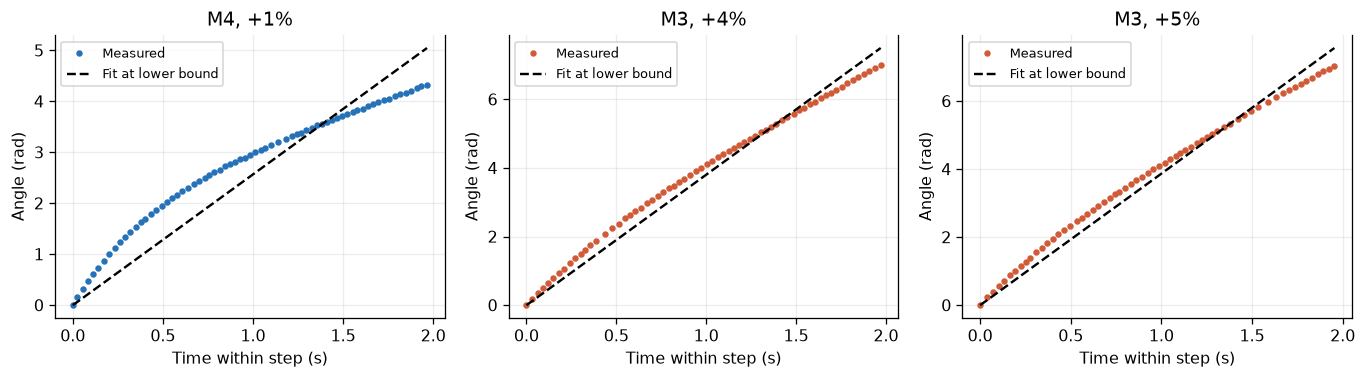

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (motor, pwm) in zip(axes, [('M4', 1), ('M3', 4), ('M3', 5)]):
    t, angle = step_segments[motor, pwm]
    row = steps[(steps['Motor'] == motor) & (steps['PWM (%)'] == pwm)].iloc[0]
    ax.plot(t, angle, '.', color=motor_colors[motor], label='Measured')
    ax.plot(t, step_model(t, row['Speed (rad/s)'], row['T (s)']), 'k--', label='Fit at lower bound')
    ax.set(title=f'{motor}, +{pwm}%', xlabel='Time within step (s)', ylabel='Angle (rad)')
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


*These three responses slow down during a constant command. The usual acceleration-from-rest equation cannot reproduce that shape. Residual motion, changing friction or a timing issue could explain it, but the curves alone do not show which cause is responsible.*

## Square wave and chirp

Both signals have an amplitude of 60% PWM and last about eight seconds, followed by one second at zero power. The square-wave period is one second, while the chirp frequency rises from 0.2 to 5 Hz.

I fit the square wave with a separate gain for each direction and one common time constant. I then keep those parameters fixed when predicting the chirp. This lets me check the model on a different recording. The square-wave fit describes the data used to estimate the parameters; the chirp is the separate test.

For these comparisons, I write the model directly in PWM units:

$$\dot\omega=\frac{K_{direction}\,u-\omega}{T_m},\qquad \dot\theta=\omega.$$

Here $u$ is PWM and $K$ is the speed gain in rad/s per % PWM. The simulation holds each logged command until the next sample and uses the actual time between samples. It starts with zero angle and zero speed. The first reading may already contain a little motion, so the start of the prediction is only approximate.


In [6]:
def signal_arrays(label):
    a = data[label]
    return (a[:, 1] - a[0, 1]) / 1000, np.deg2rad(a[:, 0] - a[0, 0]), a[:, 2]

def simulate(t, pwm, parameters, thresholds=(0, 0)):
    K_forward, K_backward, T_m = parameters
    angle, speed = np.zeros(len(t)), np.zeros(len(t))
    for i, dt in enumerate(np.diff(t)):
        u = pwm[i]
        gain = K_forward if u >= 0 else K_backward
        threshold = thresholds[0 if u >= 0 else 1]
        target = gain * u if abs(u) > threshold else 0
        decay = np.exp(-dt / T_m)
        angle[i + 1] = angle[i] + target * dt + (speed[i] - target) * T_m * (1 - decay)
        speed[i + 1] = target + (speed[i] - target) * decay
    return angle, speed

square_params = {}
square_rows = []
for motor in ['M4', 'M3']:
    t, angle, pwm = signal_arrays(f'{motor} square')
    result = least_squares(lambda p: simulate(t, pwm, p)[0] - angle,
                           [0.16, 0.16, 0.1], bounds=([0.001, 0.001, 0.005], [2, 2, 2]))
    assert result.success
    square_params[motor] = result.x
    square_rows.append([motor, *result.x])
show_table(pd.DataFrame(square_rows, columns=['Motor', 'Forward K (rad/s per %)',
                                            'Backward K (rad/s per %)', 'Square-wave T (s)']), 4)


Motor,Forward K (rad/s per %),Backward K (rad/s per %),Square-wave T (s)
M4,0.1711,0.1637,0.1181
M3,0.1802,0.1800,0.1410


I calculate measured speed with `np.gradient` and smooth it with a centred five-sample moving average. That covers roughly 0.2 seconds in these recordings. I apply the same smoothing to the predicted speed when calculating the errors, since smoothing also reduces the size of fast changes.

I also compare predictions with and without a dead zone, using the midpoint of each threshold range. None of the nonzero commands in these complex-signal recordings falls inside those small dead zones, so both predictions are the same.

$$RMSE=\sqrt{\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat y_i)^2},\qquad
Fit=100\left(1-\frac{\lVert y-\hat y\rVert}{\lVert y-\overline y\rVert}\right).$$

A negative fit means the model has more error than simply predicting the mean measured value.


In [7]:
WINDOW = 5
def smooth(values):
    return pd.Series(values).rolling(WINDOW, center=True, min_periods=1).mean().to_numpy()

def scores(measured, predicted):
    error = measured - predicted
    baseline = np.linalg.norm(measured - measured.mean())
    return np.sqrt(np.mean(error**2)), 100 * (1 - np.linalg.norm(error) / baseline)

predictions, metric_rows = {}, []
for signal in ['square', 'chirp']:
    for motor in ['M4', 'M3']:
        t, angle, pwm = signal_arrays(f'{motor} {signal}')
        raw_speed = np.gradient(angle, t)
        measured_speed = smooth(raw_speed)
        thresholds = tuple(np.mean(deadzone[motor, d]) for d in ['Forward', 'Backward'])
        for variant, limits in [('No dead zone', (0, 0)), ('With dead zone', thresholds)]:
            predicted_angle, predicted_speed = simulate(t, pwm, square_params[motor], limits)
            shown_speed = smooth(predicted_speed)
            angle_rmse, angle_fit = scores(angle, predicted_angle)
            speed_rmse, speed_fit = scores(measured_speed, shown_speed)
            predictions[motor, signal, variant] = (predicted_angle, predicted_speed, shown_speed)
            metric_rows.append([motor, signal, variant, angle_rmse, angle_fit, speed_rmse, speed_fit])
metrics = pd.DataFrame(metric_rows, columns=['Motor', 'Signal', 'Model', 'Angle RMSE (rad)',
    'Angle fit (%)', 'Speed RMSE (rad/s)', 'Speed fit (%)'])
show_table(metrics, 2)


Motor,Signal,Model,Angle RMSE (rad),Angle fit (%),Speed RMSE (rad/s),Speed fit (%)
M4,square,No dead zone,0.27,79.60,0.90,84.90
M4,square,With dead zone,0.27,79.60,0.90,84.90
M3,square,No dead zone,0.40,75.04,1.06,82.69
M3,square,With dead zone,0.40,75.04,1.06,82.69
M4,chirp,No dead zone,0.98,35.92,0.64,77.21
M4,chirp,With dead zone,0.98,35.92,0.64,77.21
M3,chirp,No dead zone,4.57,-71.22,1.32,57.60
M3,chirp,With dead zone,4.57,-71.22,1.32,57.60


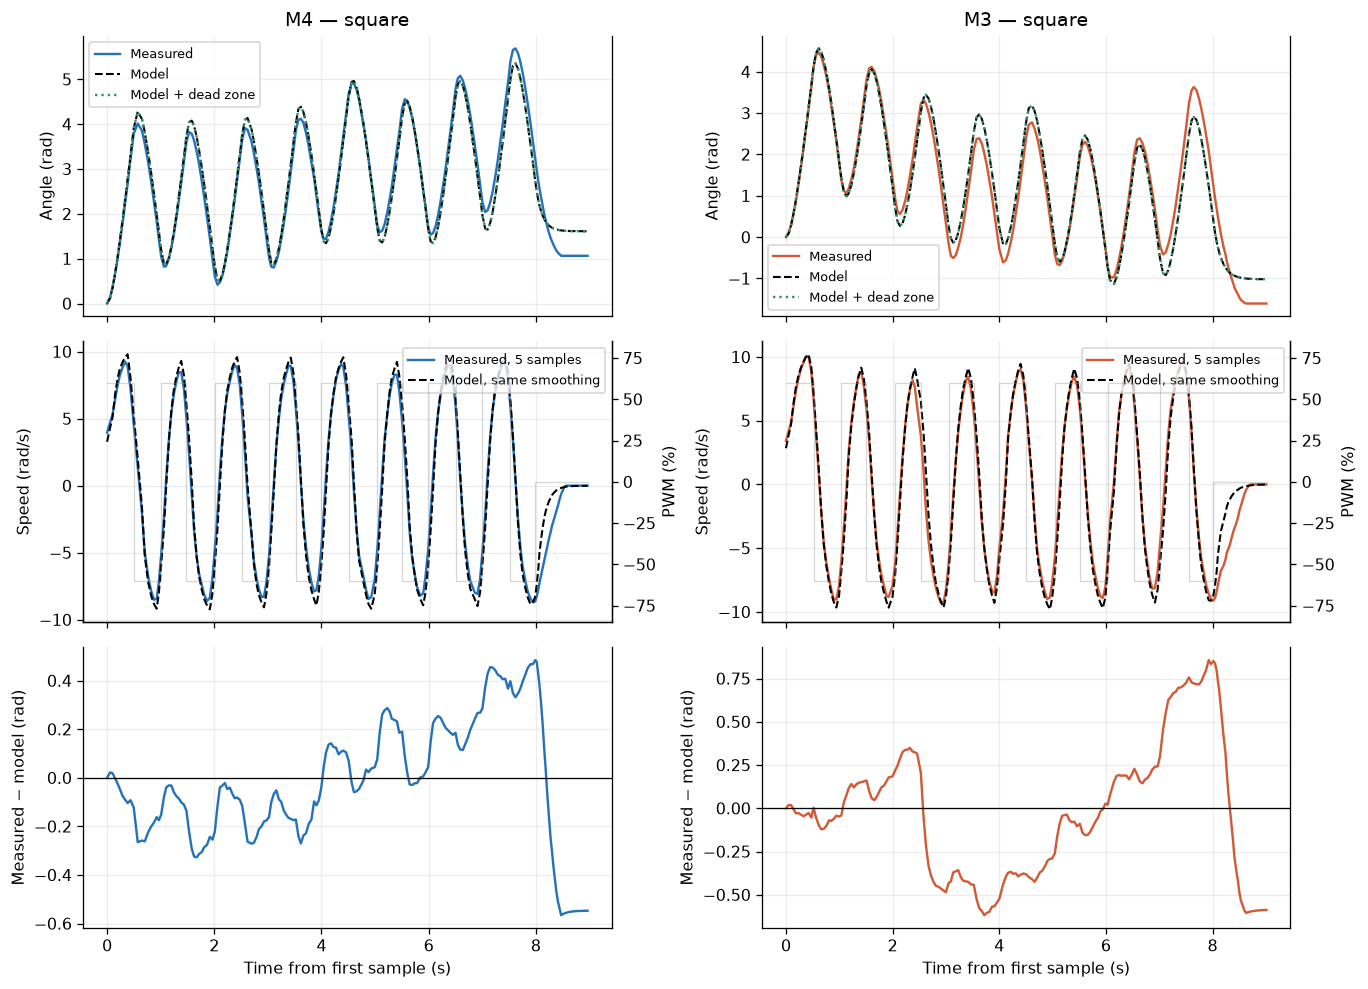

In [8]:
def comparison_plot(signal):
    fig, axes = plt.subplots(3, 2, figsize=(12, 8.7), sharex='col')
    for col, motor in enumerate(['M4', 'M3']):
        t, angle, pwm = signal_arrays(f'{motor} {signal}')
        measured_speed = smooth(np.gradient(angle, t))
        pred_angle, _, pred_speed = predictions[motor, signal, 'No dead zone']
        dz_angle, _, _ = predictions[motor, signal, 'With dead zone']
        axes[0, col].plot(t, angle, color=motor_colors[motor], label='Measured')
        axes[0, col].plot(t, pred_angle, 'k--', lw=1.3, label='Model')
        axes[0, col].plot(t, dz_angle, ':', color='#35926a', lw=1.5, label='Model + dead zone')
        axes[1, col].plot(t, measured_speed, color=motor_colors[motor], label='Measured, 5 samples')
        axes[1, col].plot(t, pred_speed, 'k--', lw=1.3, label='Model, same smoothing')
        pwm_ax = axes[1, col].twinx()
        pwm_ax.step(t, pwm, where='post', color='0.6', alpha=0.4, lw=0.8)
        pwm_ax.set(ylabel='PWM (%)', ylim=(-85, 85))
        pwm_ax.grid(False)
        axes[2, col].plot(t, angle - pred_angle, color=motor_colors[motor])
        axes[2, col].axhline(0, color='black', lw=0.8)
        axes[0, col].set(title=f'{motor} — {signal}', ylabel='Angle (rad)')
        axes[1, col].set(ylabel='Speed (rad/s)')
        axes[2, col].set(ylabel='Measured − model (rad)', xlabel='Time from first sample (s)')
        axes[0, col].legend(fontsize=8)
        axes[1, col].legend(fontsize=8, loc='upper right')
    fig.tight_layout()
    plt.show()

comparison_plot('square')


*The square-wave model follows the repeated reversals, but some angle error still builds up. The pale gray line shows PWM. The predictions with and without the dead zone overlap.*


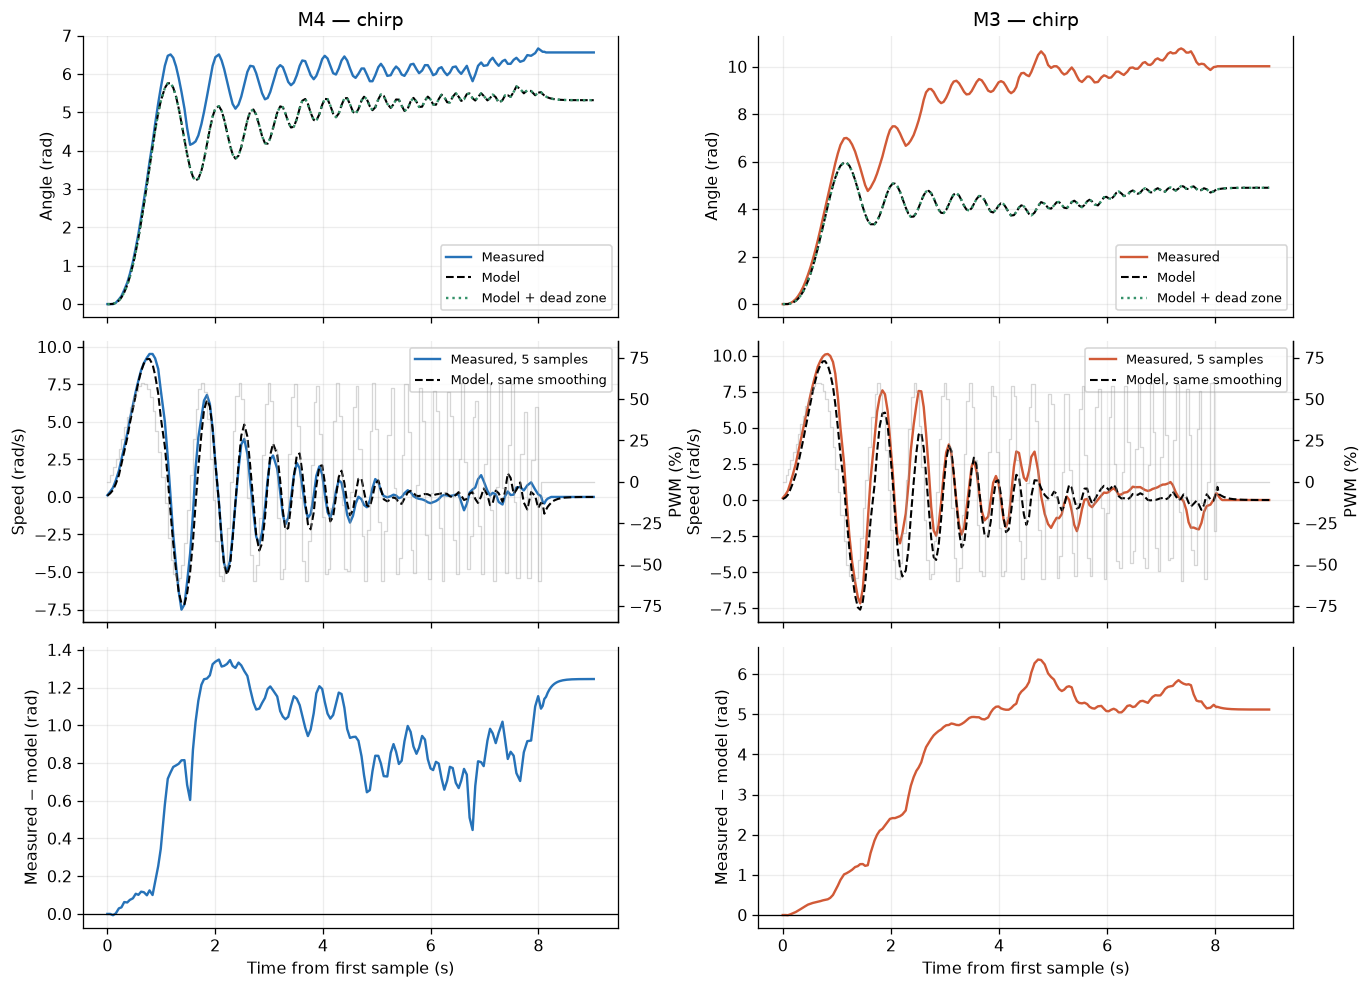

In [9]:
comparison_plot('chirp')


*The chirp uses the same parameters fitted to the square wave. The model follows some of the oscillations, but the angle error is much larger for M3.*

## Chirp amplitude against frequency

I estimate the speed and PWM amplitudes in 1.2-second windows, moving each window forward by 0.4 seconds. Each window needs at least 15 samples and one nominal cycle. A sine/cosine fit gives the amplitude, and I align the chirp timing using the recorded input only.

The model predicts this amplitude ratio:

$$\frac{A_\omega}{A_{PWM}}=\frac{\overline K}{\sqrt{1+(2\pi fT_m)^2}},$$

where $\overline K$ is the mean of the two directional gains. For this plot, I use speed before smoothing so the moving average does not reduce the high-frequency amplitudes. The estimates are still approximate because frequency changes within each window and the final cycles contain few samples.


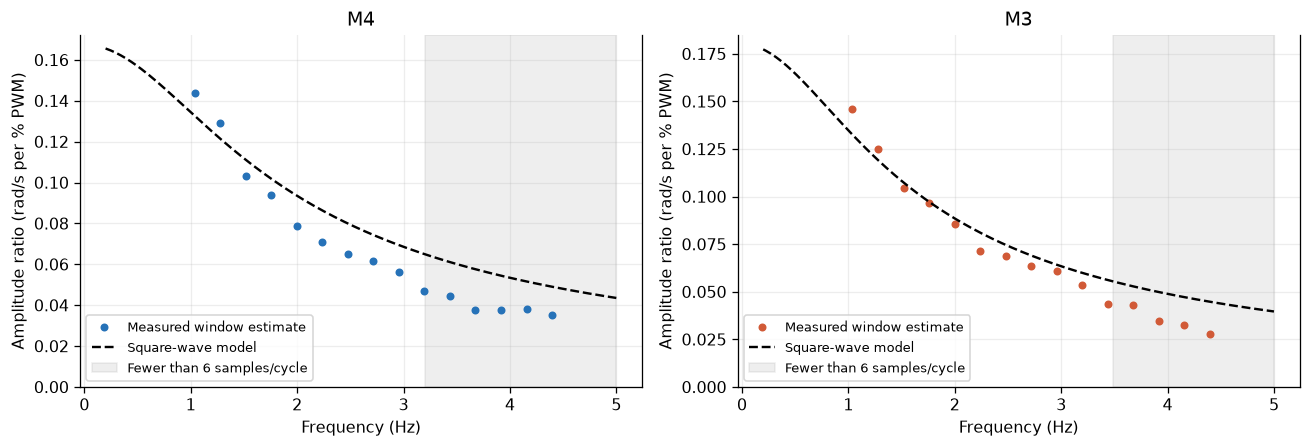

Motor,Input clock offset (s),Median active sample interval (s),Model cutoff (Hz),Samples/cycle at 5 Hz
M4,-0.006,0.052,1.347,3.838
M3,-0.001,0.048,1.129,4.181


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
frequency_rows = []
for ax, motor in zip(axes, ['M4', 'M3']):
    t, angle, pwm = signal_arrays(f'{motor} chirp')
    active_end = np.flatnonzero(pwm != 0)[-1]
    ta, ua = t[:active_end + 1], pwm[:active_end + 1]
    rate = (5.0 - 0.2) / 8.0
    def phase(seconds):
        return 2 * np.pi * (0.2 * seconds + 0.5 * rate * seconds**2)
    # Align the timing from the input, without fitting the motor response again.
    alignment = least_squares(lambda p: 60 * np.sin(phase(ta + p[0])) - ua,
                              [0.0], bounds=([-0.15], [0.15])).x[0]
    raw_speed = np.gradient(angle, t)
    centers, ratios = [], []
    for center in np.arange(0.6, ta[-1] - 0.6, 0.4):
        mask = np.abs(ta - center) <= 0.6
        frequency = 0.2 + rate * (center + alignment)
        if mask.sum() < 15 or 1.2 * frequency < 1:
            continue
        ph = phase(ta[mask] + alignment)
        design = np.column_stack([np.sin(ph), np.cos(ph), np.ones(mask.sum()), ta[mask] - center])
        speed_fit = np.linalg.lstsq(design, raw_speed[:active_end + 1][mask], rcond=None)[0]
        input_fit = np.linalg.lstsq(design, ua[mask], rcond=None)[0]
        ratio = np.hypot(*speed_fit[:2]) / np.hypot(*input_fit[:2])
        centers.append(frequency); ratios.append(ratio)
    f = np.linspace(0.2, 5, 200)
    Kf, Kb, T_m = square_params[motor]
    ax.plot(centers, ratios, 'o', ms=4, color=motor_colors[motor], label='Measured window estimate')
    ax.plot(f, np.mean([Kf, Kb]) / np.sqrt(1 + (2 * np.pi * f * T_m)**2),
            'k--', label='Square-wave model')
    dt = np.median(np.diff(ta))
    few_samples = 1 / (6 * dt)
    if few_samples < 5:
        ax.axvspan(few_samples, 5, color='grey', alpha=0.13, label='Fewer than 6 samples/cycle')
    ax.set(title=motor, xlabel='Frequency (Hz)', ylabel='Amplitude ratio (rad/s per % PWM)', ylim=(0, None))
    ax.legend(fontsize=8)
    frequency_rows.append([motor, alignment, dt, 1 / (2 * np.pi * T_m), 1 / (5 * dt)])
fig.tight_layout()
plt.show()
show_table(pd.DataFrame(frequency_rows, columns=['Motor', 'Input clock offset (s)',
    'Median active sample interval (s)', 'Model cutoff (Hz)', 'Samples/cycle at 5 Hz']))


*The speed amplitude generally gets smaller as frequency increases. The high-frequency points are less reliable because there are only a few samples in each cycle.*

## Artifacts in the recordings

I use the initial motor-off sections to check for encoder drift. I also calculate the time between consecutive samples. The timer is set to 5 ms, but reading the encoder, running the blocks and writing the file add time to each loop.


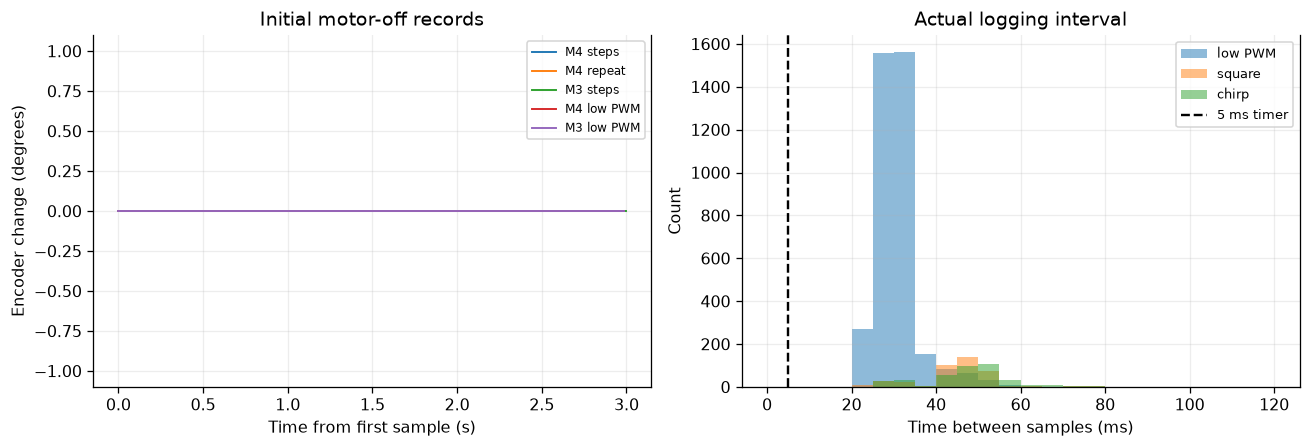

**Initial drift and clock offsets**

Recording,Samples,Span (s),Angle range (deg),First timestamp (ms)
M4 steps,101,2.976,0.000,73.458
M4 repeat,93,2.975,0.000,62.577
M3 steps,97,2.994,0.000,56.579
M4 low PWM,102,2.983,0.000,42.515
M3 low PWM,97,2.986,0.000,46.604


**Sampling intervals**

Recording,Mean (ms),Median (ms),Minimum (ms),Maximum (ms)
M4 steps,29.76,29.61,23.09,43.75
M4 repeat,32.33,31.38,26.48,50.85
M3 steps,31.19,30.56,23.86,48.09
M4 square,45.28,46.28,22.65,83.84
M3 square,45.06,46.59,22.95,74.33
M4 chirp,49.88,51.79,26.35,77.39
M3 chirp,45.44,46.45,22.78,73.29
M4 low PWM,30.01,29.48,22.33,72.49
M3 low PWM,31.20,30.48,22.78,78.48


In [11]:
drift_rows, sampling_rows = [], []
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for label in ['M4 steps', 'M4 repeat', 'M3 steps', 'M4 low PWM', 'M3 low PWM']:
    segment = split_by_pwm(data[label])[0]
    assert segment[0, 2] == 0
    t = (segment[:, 1] - segment[0, 1]) / 1000
    angle = segment[:, 0] - segment[0, 0]
    drift_rows.append([label, len(t), t[-1], np.ptp(angle), segment[0, 1]])
    axes[0].plot(t, angle, label=label, lw=1.2)
for label, a in data.items():
    dt = np.diff(a[:, 1])
    sampling_rows.append([label, dt.mean(), np.median(dt), dt.min(), dt.max()])
for signal in ['low PWM', 'square', 'chirp']:
    intervals = np.concatenate([np.diff(data[f'{m} {signal}'][:, 1]) for m in ['M4', 'M3']])
    axes[1].hist(intervals, bins=np.arange(0, 125, 5), alpha=0.5, label=signal)
axes[0].set(title='Initial motor-off records', xlabel='Time from first sample (s)',
            ylabel='Encoder change (degrees)', ylim=(-1.1, 1.1))
axes[0].legend(fontsize=7.5)
axes[1].axvline(5, color='black', ls='--', label='5 ms timer')
axes[1].set(title='Actual logging interval', xlabel='Time between samples (ms)', ylabel='Count')
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
display(Markdown('**Initial drift and clock offsets**'))
show_table(pd.DataFrame(drift_rows, columns=['Recording', 'Samples', 'Span (s)',
    'Angle range (deg)', 'First timestamp (ms)']))
display(Markdown('**Sampling intervals**'))
sampling = pd.DataFrame(sampling_rows, columns=['Recording', 'Mean (ms)', 'Median (ms)',
                                               'Minimum (ms)', 'Maximum (ms)'])
show_table(sampling, 2)


*The motor-off traces overlap because the encoder values stay constant. There is no measurable drift during these short checks. After a powered run, the final angle does not need to return to zero.*

I measure power-off movement between the first and last samples of each zero-PWM section. This can miss movement before the first sample. The program sets power to zero before the final floating stop, so I treat this as movement after power-off rather than assume every section is free coasting.


M4: median power-off movement 10.0°, maximum 21.0°; median observed reversal interval 0.099 s.
M3: median power-off movement 14.0°, maximum 32.0°; median observed reversal interval 0.139 s.


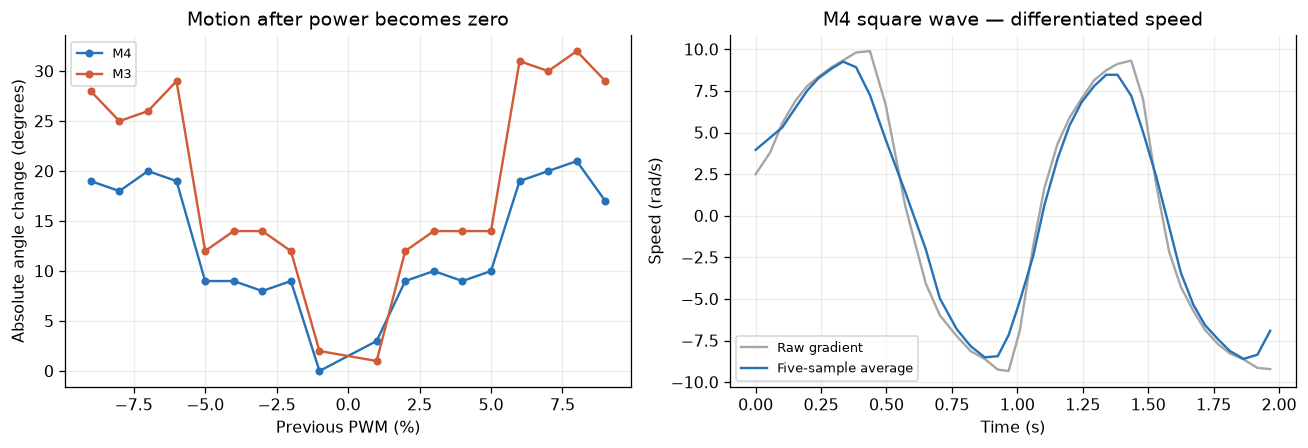

**Speed variation before and after smoothing**

Motor,Raw speed SD (rad/s),Smoothed speed SD (rad/s),RMS raw minus smoothed (rad/s)
M4,6.513,5.932,0.935
M3,6.702,6.122,0.955


The speed variation includes real acceleration; it is not a pure sensor-noise estimate.

In [12]:
coast_rows, noise_rows, reversal_rows = [], [], []
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for motor in ['M4', 'M3']:
    segments = split_by_pwm(data[f'{motor} low PWM'])
    for before, off in zip(segments, segments[1:]):
        if before[0, 2] != 0 and off[0, 2] == 0:
            motion = off[-1, 0] - off[0, 0]
            coast_rows.append([motor, int(before[0, 2]), motion])
    rows = [r for r in coast_rows if r[0] == motor]
    axes[0].plot([r[1] for r in rows], [abs(r[2]) for r in rows], 'o-',
                 ms=4, color=motor_colors[motor], label=motor)
    a = data[f'{motor} square']
    t, angle, pwm = signal_arrays(f'{motor} square')
    raw = np.gradient(angle, t)
    filtered = smooth(raw)
    residual = raw - filtered
    noise_rows.append([motor, np.std(raw), np.std(filtered), np.sqrt(np.mean(residual**2))])
    changes = np.flatnonzero(pwm[1:] * pwm[:-1] < 0) + 1
    for i in changes:
        later = np.arange(i + 1, min(i + 9, len(t)))
        opposite = later[np.sign(pwm[i]) * (angle[later] - angle[later - 1]) > 0]
        if len(opposite):
            reversal_rows.append([motor, t[opposite[0]] - t[i]])
    if motor == 'M4':
        mask = t <= 2
        axes[1].plot(t[mask], raw[mask], color='0.65', label='Raw gradient')
        axes[1].plot(t[mask], filtered[mask], color=motor_colors[motor], label='Five-sample average')
axes[0].set(title='Motion after power becomes zero', xlabel='Previous PWM (%)',
            ylabel='Absolute angle change (degrees)')
axes[1].set(title='M4 square wave — differentiated speed', xlabel='Time (s)', ylabel='Speed (rad/s)')
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
display(Markdown('**Speed variation before and after smoothing**'))
show_table(pd.DataFrame(noise_rows, columns=['Motor', 'Raw speed SD (rad/s)',
    'Smoothed speed SD (rad/s)', 'RMS raw minus smoothed (rad/s)']))
display(Markdown('The speed variation includes real acceleration; it is not a pure sensor-noise estimate.'))
coasting = pd.DataFrame(coast_rows, columns=['Motor', 'Previous PWM (%)', 'Off-block angle change (deg)'])
reversals = pd.DataFrame(reversal_rows, columns=['Motor', 'Observed reversal interval (s)'])
for motor in ['M4', 'M3']:
    off = coasting[coasting['Motor'] == motor]['Off-block angle change (deg)'].abs()
    rev = reversals[reversals['Motor'] == motor]['Observed reversal interval (s)']
    print(f'{motor}: median power-off movement {off.median():.1f}°, maximum {off.max():.1f}°; '
          f'median observed reversal interval {rev.median():.3f} s.')


*The wheels keep moving briefly after power-off and take time to reverse. Inertia, friction, backlash and logging delay can all contribute, so the observed reversal time cannot be attributed to backlash alone.*

The encoder records whole degrees. Calculating speed from these readings can make small changes look noisy, especially when the sample intervals vary. Smoothing makes the speed easier to read, but also softens the reversals. For odometry, I would use the measured angle changes with their actual timestamps.

## Discussion

Most low-power steps fit well, but the chirp angle fits drop to 35.9% for M4 and −71.2% for M3. The negative M3 result means its prediction is worse than using the mean measured angle. A good fit to the square wave therefore does not guarantee a good chirp prediction.

There was no measurable drift in the initial motor-off checks. The median logging intervals were 29.5–51.8 ms, and both motors kept moving after power-off. These timing and motion differences matter when calculating position from encoder readings.

## Conclusion

The simple model was useful for the low-power steps, but the chirp exposed larger errors, especially for M3. The wheels also kept turning briefly after power-off. I would keep separate parameters for the two motors and check them over a wider PWM range. That would make me more confident using the model for precise movement.
